# 07 · Empirical convergence in δ and Δ

There are two discretisation parameters: δ, the flux-level spacing, and
Δ, the mesh width of $g_\Delta$. Each test problem starts from levels that
are multiples of 0.1, so the data are exact for every δ = 0.1·2⁻ᵏ. Then δ
enters only through δ-fans, and Δ only through $g_\Delta$.

Errors against a fine numerical reference are measured as follows:

* $\|\theta-\theta_{\rm ref}\|_{L^1}$, where both are step functions;
* the maximum of $\left|\int_a^x (u-u_{\rm ref})\right|$ on 801 sample
  points, each from exact cell integrals; this is not the continuum supremum.
  This is robust where u blows up at zeros.

These are observations, not proofs. Set `power` below to choose the flux
exponent. This notebook uses four levels; run
`python convergence.py --power 1.5 --power 3` for five-level general-power studies.
Initial theta data are shared across powers; the physical initial profiles
consequently depend on the exponent.

In [1]:
# Use the local checkout if present; otherwise install from GitHub (needs the repository to be public).
import sys, subprocess, importlib.util
from pathlib import Path
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/hetfront/__init__.py").is_file()), None)
if local_src is not None:
    sys.path.insert(0, str(local_src))
elif importlib.util.find_spec("hetfront") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/parasuramv/heterogeneous-front-tracking"])
import numpy as np
import matplotlib.pyplot as plt
import hetfront
from hetfront import (HeteroFrontTracker, PeriodicHeteroFrontTracker, MultiplicativeFlux,
                      PiecewiseAffine, trajectory)
from hetfront.visualization import (observe_tracker, plot_spacetime, plot_profile,
                                    plot_heterogeneity, plot_diagnostics, plot_circle, overview)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
print("hetfront", hetfront.__version__, "from", "local checkout" if local_src else "installed package")

hetfront 0.1.0 from local checkout


In [2]:
from dataclasses import replace
from hetfront.studies import PROBLEMS, standard_study, fitted_order
power = 2.0  # change to 1.5 or 3.0 to rerun this experiment
studies = {name: standard_study(replace(PROBLEMS[name], power=power), levels=4, depth=2)
           for name in PROBLEMS}
for name, st in studies.items():
    print(f"{name:22s} reference: δ = {st['reference']['delta']:.4g}, {st['reference']['nodes']} nodes, "
          f"{st['reference']['events']} events, {st['reference']['seconds']:.1f} s")

line-well-signed       reference: δ = 0.003125, 512 nodes, 54367 events, 3.1 s
line-sign-changing     reference: δ = 0.003125, 512 nodes, 40884 events, 2.5 s
circle-well-signed     reference: δ = 0.003125, 512 nodes, 194016 events, 5.8 s
circle-sign-changing   reference: δ = 0.003125, 512 nodes, 54671 events, 1.6 s


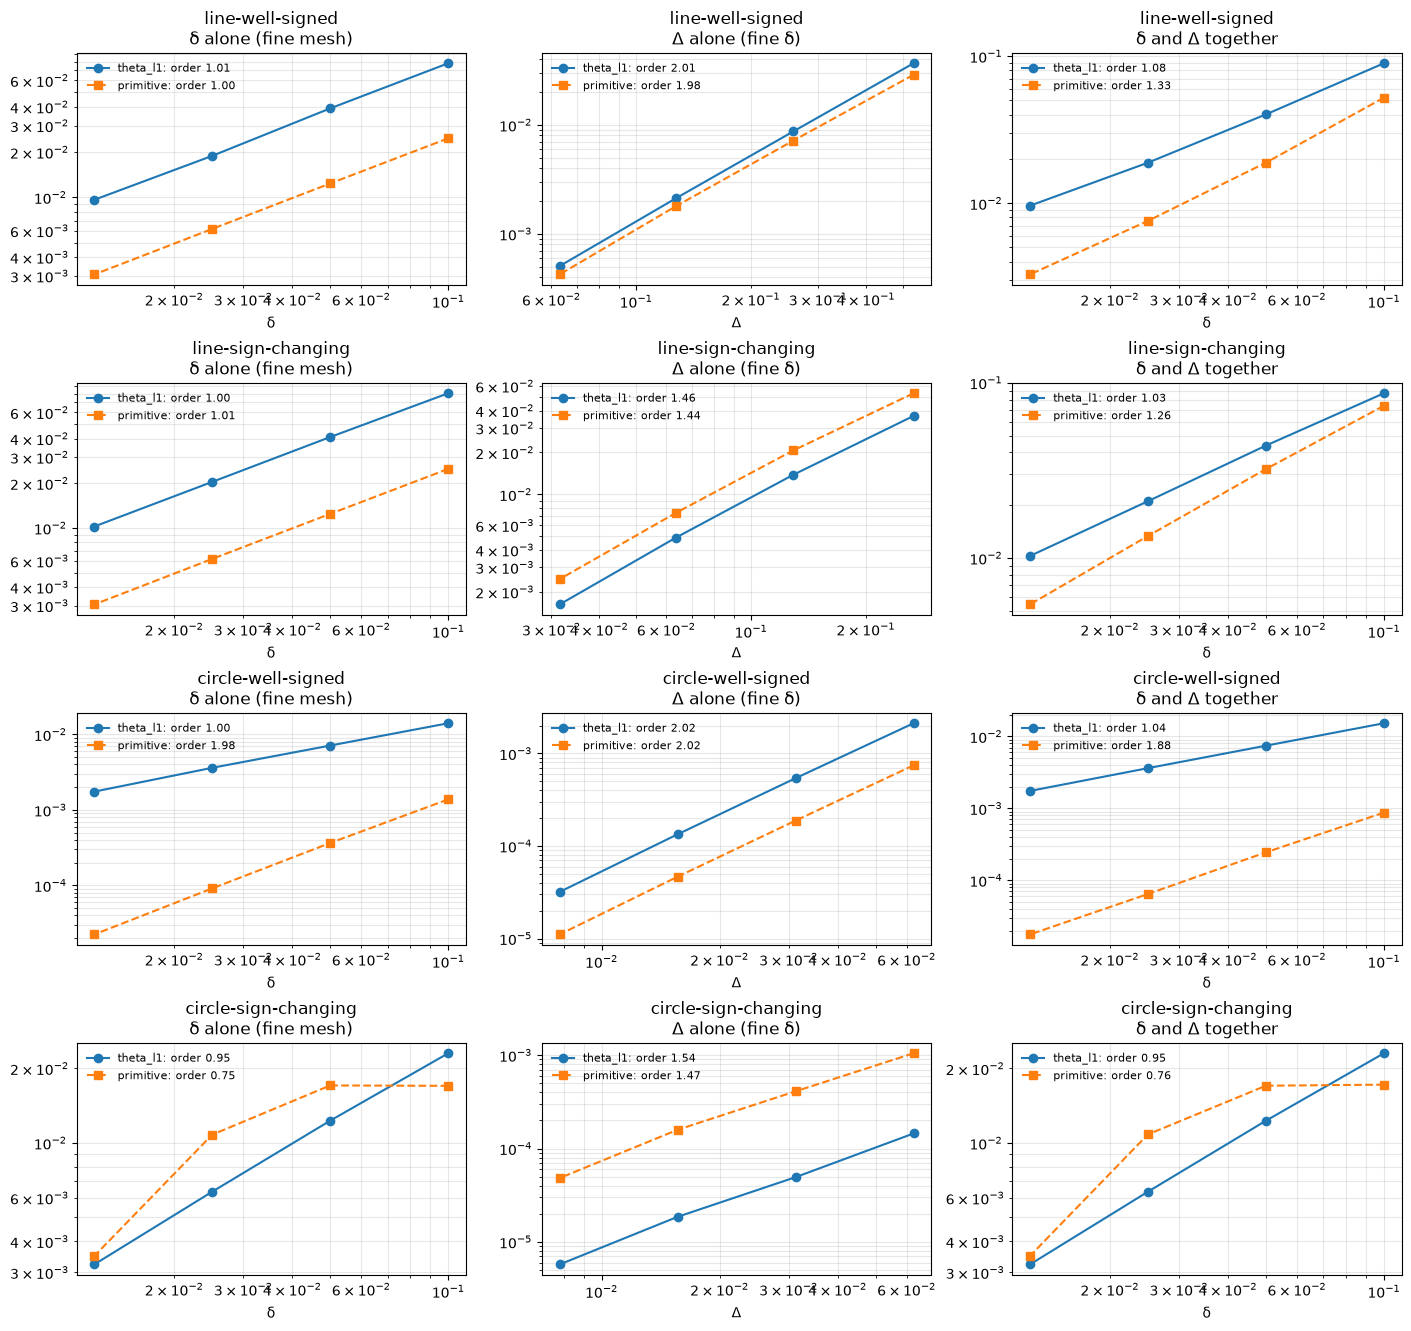

In [3]:
fig, axes = plt.subplots(len(studies), 3, figsize=(14, 3.3 * len(studies)), constrained_layout=True)
for row, (name, st) in zip(axes, studies.items()):
    for ax, kind in zip(row, ("delta", "mesh", "joint")):
        rows = st[kind]
        x = np.array([r["h"] if kind == "mesh" else r["delta"] for r in rows])
        for key, style in (("theta_l1", "o-"), ("primitive", "s--")):
            y = np.array([r[key] for r in rows])
            ax.loglog(x, y, style, label=f"{key}: order {fitted_order(x, y):.2f}")
        ax.set(xlabel="Δ" if kind == "mesh" else "δ",
               title=f"{name}\n{ {'delta': 'δ alone (fine mesh)', 'mesh': 'Δ alone (fine δ)', 'joint': 'δ and Δ together'}[kind] }")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8, frameon=False)
plt.show()

## What we see for the default $p=2$

These descriptions refer to the quadratic baseline; changing `power`
requires interpreting the new measurements rather than reusing these rates.

* **δ alone: approximately first order in these runs.** This does not
  follow from a uniform $O(\delta)$ front-speed error: $s(\theta)$ is
  only half-Hölder at zero, and the first fan step has a speed gap of
  order $\sqrt\delta$. The measured integrated error is a different quantity.
* **Δ alone, well-signed g: approximately second order in these runs.**
  Smooth-coefficient interpolation has $O(\Delta^2)$ error; propagation
  of that rate to the numerical solution is not proved here.
* **Δ alone, near transverse zeros: about 3/2.** A plausible explanation:
  at an exactly inserted transverse zero of a one-sided $C^2$ coefficient,
  $|g_\Delta-g|=O(\Delta|x-z|)$ gives relative error $O(\Delta)$.
  Integrating $O(\Delta)|x-z|^{-1/2}$ over the adjacent cell gives
  $O(\Delta^{3/2})$. This local calculation is not a dynamic rate proof.
* **Both together: first order**, dominated by δ.

The working conjecture is that the scheme converges to the selected entropy
solution, via uniform approximation of $g$ by smoother heterogeneities.
The numbers above are consistent with it.

## Recorded general-power mesh refinements

The checked-in five-level experiments use $p=3/2,3$, with delta-only,
mesh-only and joint refinements for all four problems. The plot below
reads their recorded mesh-only errors. Full settings, reference checks,
and the limits of the near-zero heuristic are in
[the convergence report](../docs/convergence-2026-10-15.md).
These are comparisons against numerical references, not exact solutions.

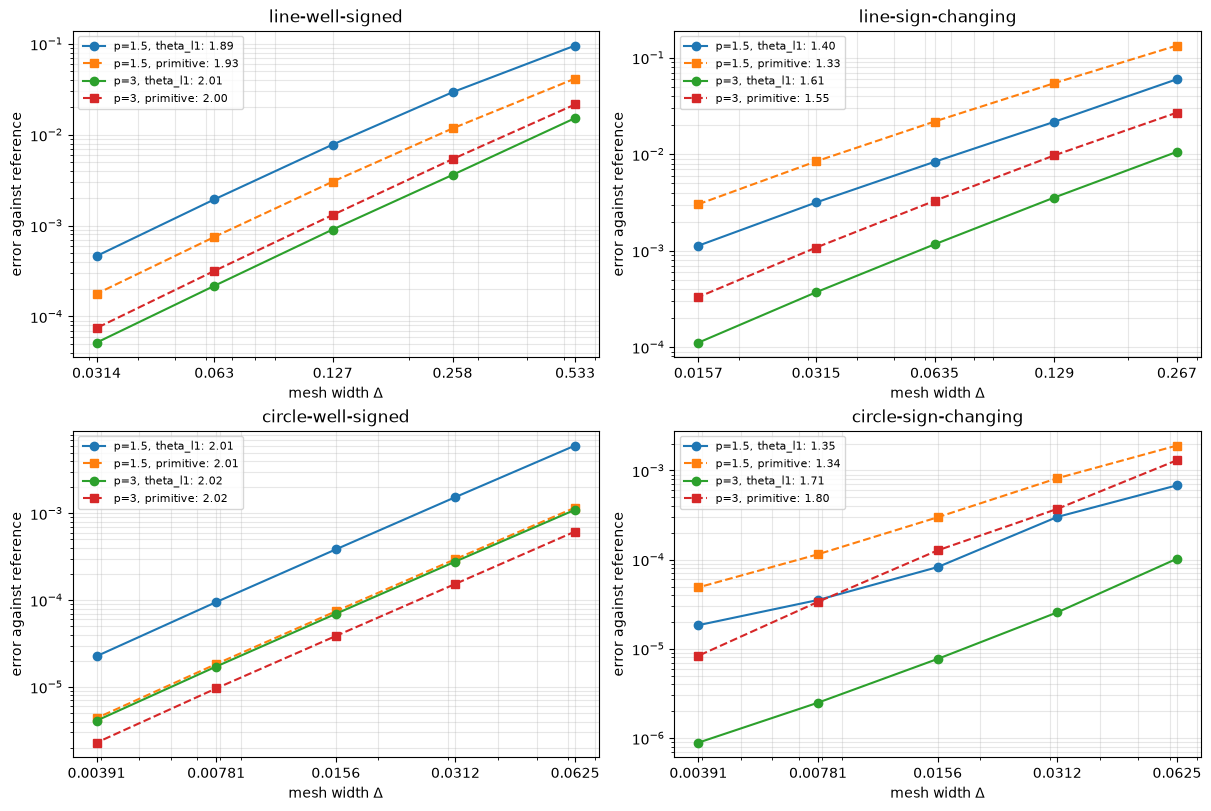

In [4]:
import json
from matplotlib.ticker import NullFormatter
data_dir = local_src.parent / "docs/data/convergence-2026-10-15" if local_src else None
records = [json.loads(path.read_text()) for path in sorted(data_dir.glob("*.json"))] if data_dir else []
if not records:
    print("Recorded results require the repository checkout; see the convergence report.")
else:
    assert {(r["problem"], r["power"]) for r in records} == {(name, p) for name in PROBLEMS for p in (1.5, 3.)}
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, name in zip(axes.flat, PROBLEMS):
        for record in records:
            if record["problem"] != name:
                continue
            rows = record["mesh"]
            for metric, style in (("theta_l1", "o-"), ("primitive", "s--")):
                h = [r["h"] for r in rows]
                err = [r[metric] for r in rows]
                order = fitted_order(h, err)
                ax.loglog(h, err, style, label=f"p={record['power']:g}, {metric}: {order:.2f}")
        ax.set(title=name, xlabel="mesh width Δ", ylabel="error against reference")
        ax.set_xticks(h, labels=[f"{value:.3g}" for value in h])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.grid(True, which="both", alpha=.3)
        ax.legend(fontsize=8)
    plt.show()